# Chronos LoRA: 기존 LOBO 실험과 EOS loss 분리 검증

**03 갈무리:** 기존 LoRA는 중앙값 RMSE만 보면 zero-shot과 비슷하지만 예측 분포가 크게 악화됐습니다. 후속 실험에서 **출력 EOS loss만 제외**하면 macro 중앙값 RMSE가 `0.016176 → 0.014894`, 평균 예측 RMSE가 `0.294040 → 0.015011`로 개선됐습니다. 모든 배터리·지표에서 좋아진 것은 아닙니다.

이 노트북의 앞부분 실행 셀은 **기존 EOS 포함 + full-data refit 프로토콜**을 재현합니다. 마지막 「갈무리」 절은 별도로 실행한 EOS loss 제외 진단의 저장 결과를 읽습니다. `FORCE_RERUN=True`는 기존 실험을 다시 실행하며 EOS 제외 학습으로 바뀌지 않습니다. 후속 결과는 학습 seed 42의 사후 진단이고, 04용 최종 검증 모델로 확정한 결과는 아닙니다.

**Outer LOBO:** 평가 배터리 1개는 학습과 epoch 선택에서 제외합니다.

**Epoch 선택:** 나머지 3개 배터리 각각의 뒤쪽 20%를 validation target으로 사용합니다. Train window의 마지막 target은 경계 이전, validation window의 첫 target은 경계 이후입니다. 경계에 걸친 target window는 제외하며 validation context에는 그 시점까지 관측된 과거가 들어갑니다.

**Refit:** 배터리별 validation RMSE의 평균으로 epoch를 고른 후, 새로운 모델을 생성하여 3개 배터리의 전체 윈도우로 선택된 epoch만큼 학습합니다. 검증에서 개선이 없으면 epoch 0을 선택할 수 있습니다. 평가 배터리 결과는 이 결정에 쓰지 않습니다.

기본값은 학습 seed 42 한 개와 추론 seed 42/43/44입니다. 추론 seed 반복은 학습 초기화 반복을 대신하지 않습니다. 추가 학습 반복은 `train_seeds`에 지정하세요.

이전 노트북과 실행 출력은 `archive/20260923_before_improvements/`에 보관했습니다.

In [1]:
from pathlib import Path
import sys

# Works with the kernel started from the project root or notebooks/.
PROJECT_ROOT = next(
    p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (p / "data" / "raw").is_dir() and (p / "src" / "soh_experiment.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.soh_experiment import (
    load_config, load_soh, make_windows, temporal_split,
    find_zeroshot, find_lobo, run_zeroshot, run_lobo, verify_saved_run,
)
from src.soh_plots import forecast_grid, horizon_comparison, validation_curves, window_comparison

CONFIG = load_config(PROJECT_ROOT)
FORCE_RERUN = False  # True: new run directory; False: reuse only verified compatible artifacts.
print("Project:", PROJECT_ROOT)
print(CONFIG)


Project: C:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh
ExperimentConfig(model_id='amazon/chronos-t5-base', revision='ad294eaacead15db499b740ea4122266dd2a81a2', battery_ids=('B0005', 'B0006', 'B0007', 'B0018'), context_length=64, prediction_length=16, device='auto', inference_batch_size=16, num_samples=100, inference_seeds=(42, 43, 44), temperature=1.0, top_k=50, top_p=1.0, train_seeds=(42,), batch_size=16, learning_rate=0.0001, weight_decay=0.0, lora_rank=8, lora_alpha=16, lora_dropout=0.05, max_epochs=10, validation_fraction=0.2, validation_samples=32, validation_seed=31415, patience=3, min_delta=1e-05)


## Fold와 시간 경계 확인
Validation target이 train context 또는 train target에 들어가지 않도록 target 시간으로 분할합니다. 이 검증은 같은 학습 배터리의 미래 구간이며, 새로운 배터리로의 일반화는 outer LOBO에서 평가합니다.

In [2]:
soh_data = load_soh(PROJECT_ROOT, CONFIG)
split_rows = []
for battery, series in soh_data.items():
    training, validation, cutoff = temporal_split(series, CONFIG)
    split_rows.append({
        "battery": battery, "train_windows": len(training["target"]),
        "validation_windows": len(validation["target"]),
        "train_target_last_cycle": int(training["forecast_start"][-1] + CONFIG.prediction_length - 1),
        "validation_target_first_cycle": int(validation["forecast_start"][0]),
    })
display(pd.DataFrame(split_rows))
display(pd.DataFrame([{"test": b, "train": ", ".join(x for x in CONFIG.battery_ids if x != b)} for b in CONFIG.battery_ids]))

,battery,train_windows,validation_windows,train_target_last_cycle,validation_target_first_cycle
0,B0005,55,19,134,135
1,B0006,55,19,134,135
2,B0007,55,19,134,135
3,B0018,26,12,105,106


,test,train
0,B0005,"B0006, B0007, B0018"
1,B0006,"B0005, B0007, B0018"
2,B0007,"B0005, B0006, B0018"
3,B0018,"B0005, B0006, B0007"


## 공통 함수로 4개 fold 실행
Seed를 모델·LoRA 생성 전에 고정합니다. Validation 추론은 다음 epoch의 학습 난수에 영향을 주지 않습니다. 매 fold의 adapter, loss, 선택 과정, 원시 예측 samples를 저장합니다. 호환되는 baseline이 없으면 자동 생성합니다.

In [3]:
LORA_RUN = None if FORCE_RERUN else find_lobo(PROJECT_ROOT, CONFIG)
LORA_RUN = LORA_RUN or run_lobo(PROJECT_ROOT, CONFIG)
manifest = json.loads((LORA_RUN / "manifest.json").read_text(encoding="utf-8"))
ZERO_RUN = Path(manifest["zeroshot_run"])
print("LoRA run:", LORA_RUN)
print("Zero-shot reference:", ZERO_RUN)
display(verify_saved_run(ZERO_RUN, PROJECT_ROOT, CONFIG))
display(verify_saved_run(LORA_RUN, PROJECT_ROOT, CONFIG))

LoRA run: C:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\results\runs\20260923T063628Z_lora_2df6cb
Zero-shot reference: C:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\results\runs\20260923T063348Z_zeroshot_b57856


{'run_id': '20260923T063348Z_zeroshot_b57856',
 'metric_rows_verified': 32,
 'artifacts_verified': 17,
 'status': 'passed'}

{'run_id': '20260923T063628Z_lora_2df6cb',
 'metric_rows_verified': 24,
 'artifacts_verified': 28,
 'status': 'passed'}

## Validation 선택 결과
Epoch 0은 adapter가 아직 학습되지 않은 상태입니다. 선택된 epoch와 refit loss를 모두 확인합니다.

,test,train_seed,selected_epoch,refit_losses
0,B0005,42,9,"[2.243235930735931, 2.240327380952381, 2.20542..."
1,B0006,42,10,"[2.1717397186147185, 2.1631493506493507, 2.130..."
2,B0007,42,9,"[2.2890963203463204, 2.2772591991341993, 2.233..."
3,B0018,42,7,"[2.175064372659176, 2.1523876404494384, 2.1177..."


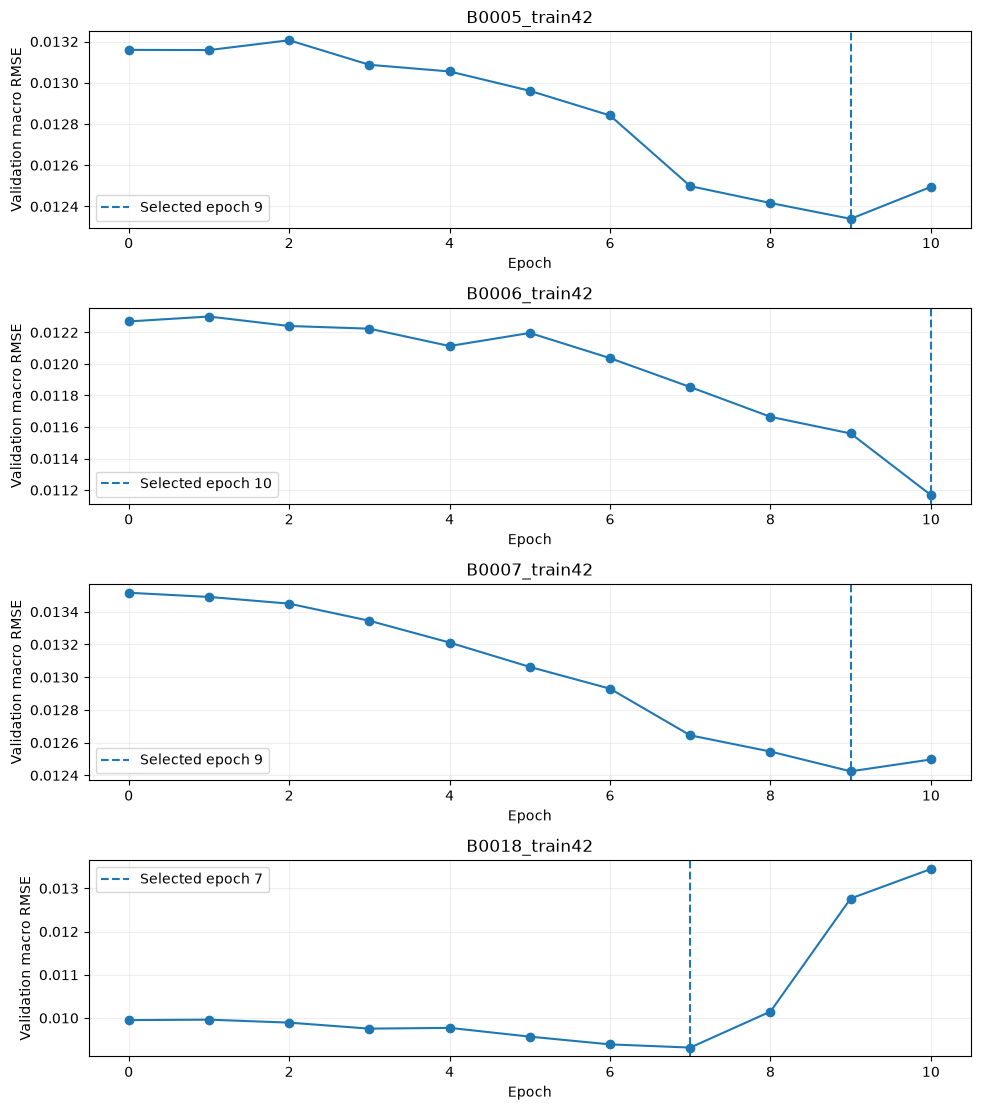

In [4]:
display(pd.DataFrame([
    {"test": fold["test_battery"], "train_seed": fold["train_seed"],
     "selected_epoch": fold["selected_epoch"], "refit_losses": fold["refit_losses"]}
    for fold in manifest["folds"]
]))
validation_curves(LORA_RUN)
plt.show()

## 동일 조건 비교
숫자를 직접 입력하지 않고 저장된 예측에서 계산한 표입니다. RMSE와 MAE의 improvement가 양수이면 LoRA가 더 좋습니다. 추론 seed별 macro 점수와 배터리별 점수를 함께 봅니다.

In [5]:
display(pd.read_csv(LORA_RUN / "summary.csv"))
comparison = pd.read_csv(LORA_RUN / "paired_comparison.csv")
display(comparison.groupby(["estimator", "battery"])[["rmse_zero", "rmse_lora", "rmse_improvement", "mae_zero", "mae_lora"]].mean())
display(pd.read_csv(LORA_RUN / "paired_macro.csv"))
coverage = pd.read_csv(LORA_RUN / "metrics.csv")
display(coverage.groupby("battery")[["coverage80", "width80"]].mean())

,model,estimator,rmse_mean,rmse_std,mae_mean,mae_std,n_runs
0,LoRA,mean,0.294040,0.004696,0.183321,0.001803,3
1,LoRA,median,0.016176,0.000020,0.010950,0.000045,3


rmse_zero  rmse_lora  rmse_improvement  mae_zero  mae_lora
estimator battery                                                            
mean      B0005     0.013980   0.549893         -0.535912  0.009507  0.369673
          B0006     0.020228   0.172935         -0.152707  0.013585  0.109076
          B0007     0.016665   0.235309         -0.218643  0.009406  0.111365
          B0018     0.023288   0.218023         -0.194735  0.016995  0.143169
median    B0005     0.012601   0.013148         -0.000547  0.009050  0.008829
          B0006     0.018900   0.019232         -0.000332  0.012889  0.012004
          B0007     0.011423   0.009454          0.001968  0.007927  0.006199
          B0018     0.022303   0.022868         -0.000566  0.016563  0.016767

,train_seed,inference_seed,estimator,rmse_lora,rmse_zero,mae_lora,mae_zero,rmse_improvement,mae_improvement,rmse_improvement_pct
0,42,42,mean,0.289765,0.017435,0.181969,0.012020,-0.272330,-0.169949,-1561.969220
1,42,42,median,0.016178,0.016251,0.010980,0.011556,0.000073,0.000576,0.449451
2,42,43,mean,0.299066,0.017970,0.182626,0.012224,-0.281096,-0.170402,-1564.245356
3,42,43,median,0.016195,0.016482,0.010899,0.011639,0.000288,0.000740,1.744656
4,42,44,mean,0.293289,0.020216,0.185368,0.012876,-0.273073,-0.172492,-1350.800851
5,42,44,median,0.016155,0.016187,0.010971,0.011626,0.000032,0.000655,0.198974


,coverage80,width80
battery,,
B0005,0.838951,0.542639
B0006,0.794710,0.047767
B0007,0.691948,0.073817
B0018,0.922563,0.087776


## Horizon 및 예측 시작점별 비교
Window별 RMSE 차이의 평균은 전체 RMSE 차이와 다릅니다. 거의 0인 차이는 허용오차에 따라 tied로 분류하여 improved/worsened와 중복되지 않게 합니다.

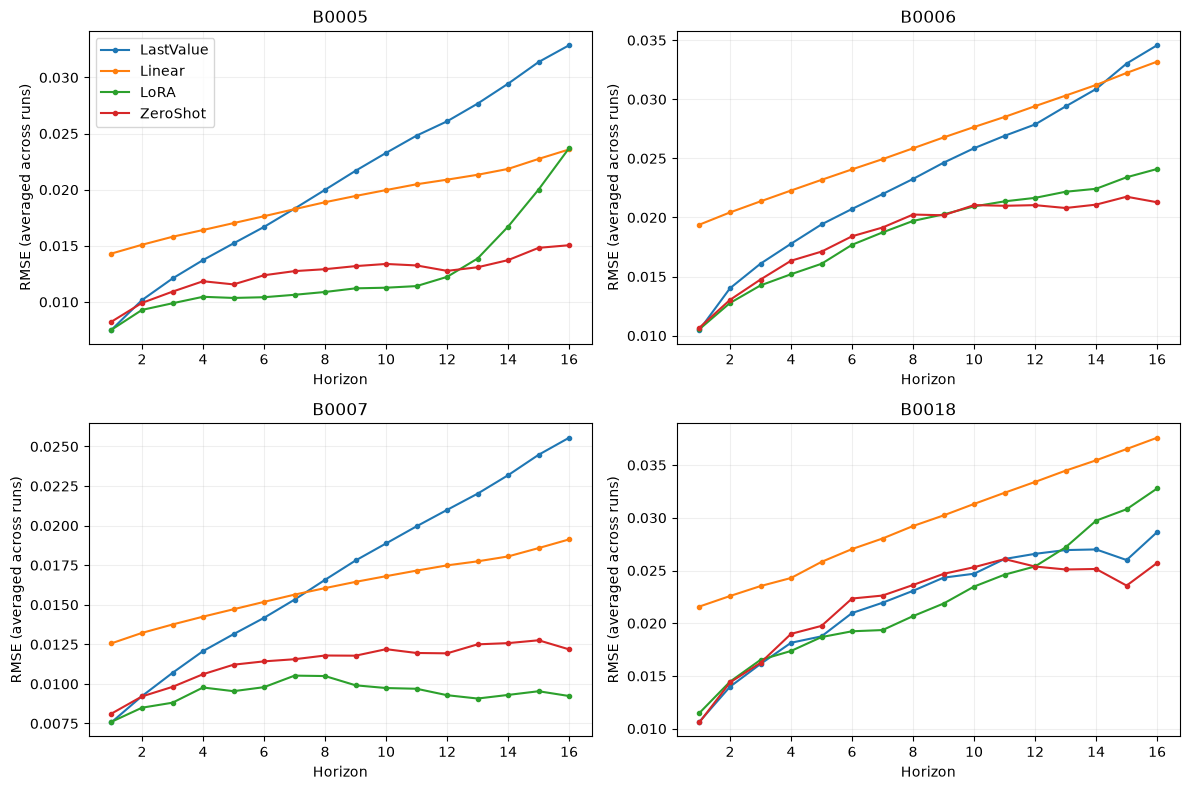

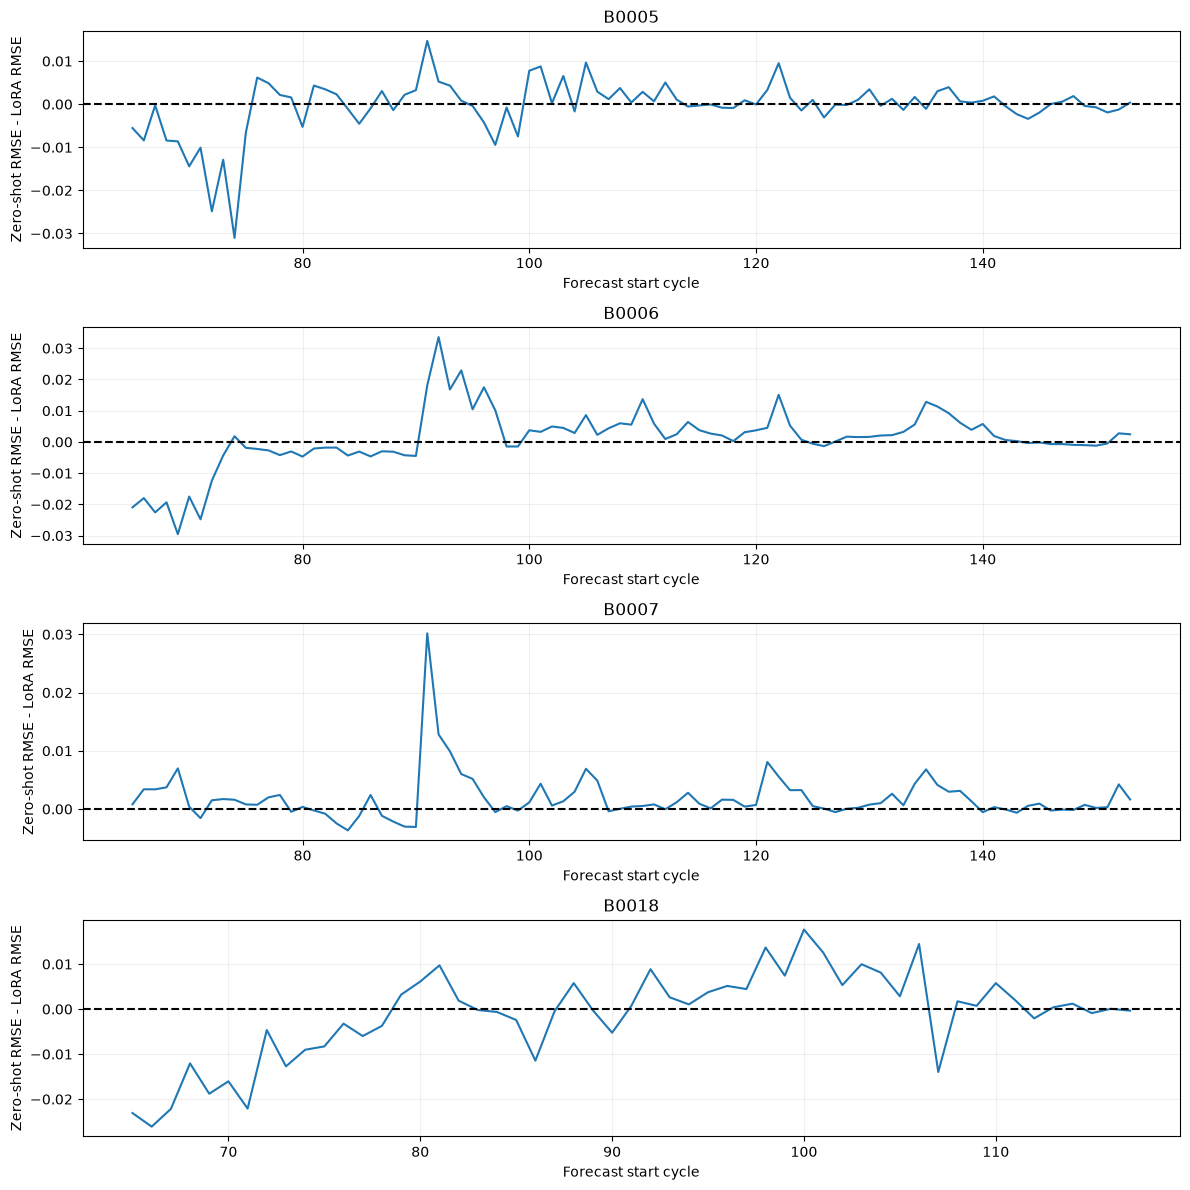

outcome,improved,tied,worsened
battery,,,
B0005,0.543071,0.000000,0.456929
B0006,0.591760,0.000000,0.408240
B0007,0.719101,0.018727,0.262172
B0018,0.553459,0.000000,0.446541


In [6]:
horizon_comparison(ZERO_RUN, LORA_RUN)
plt.show()
window_comparison(LORA_RUN)
plt.show()
paired_windows = pd.read_csv(LORA_RUN / "paired_windows.csv")
display(pd.crosstab(
    paired_windows.loc[paired_windows.estimator == "median", "battery"],
    paired_windows.loc[paired_windows.estimator == "median", "outcome"],
    normalize="index",
))

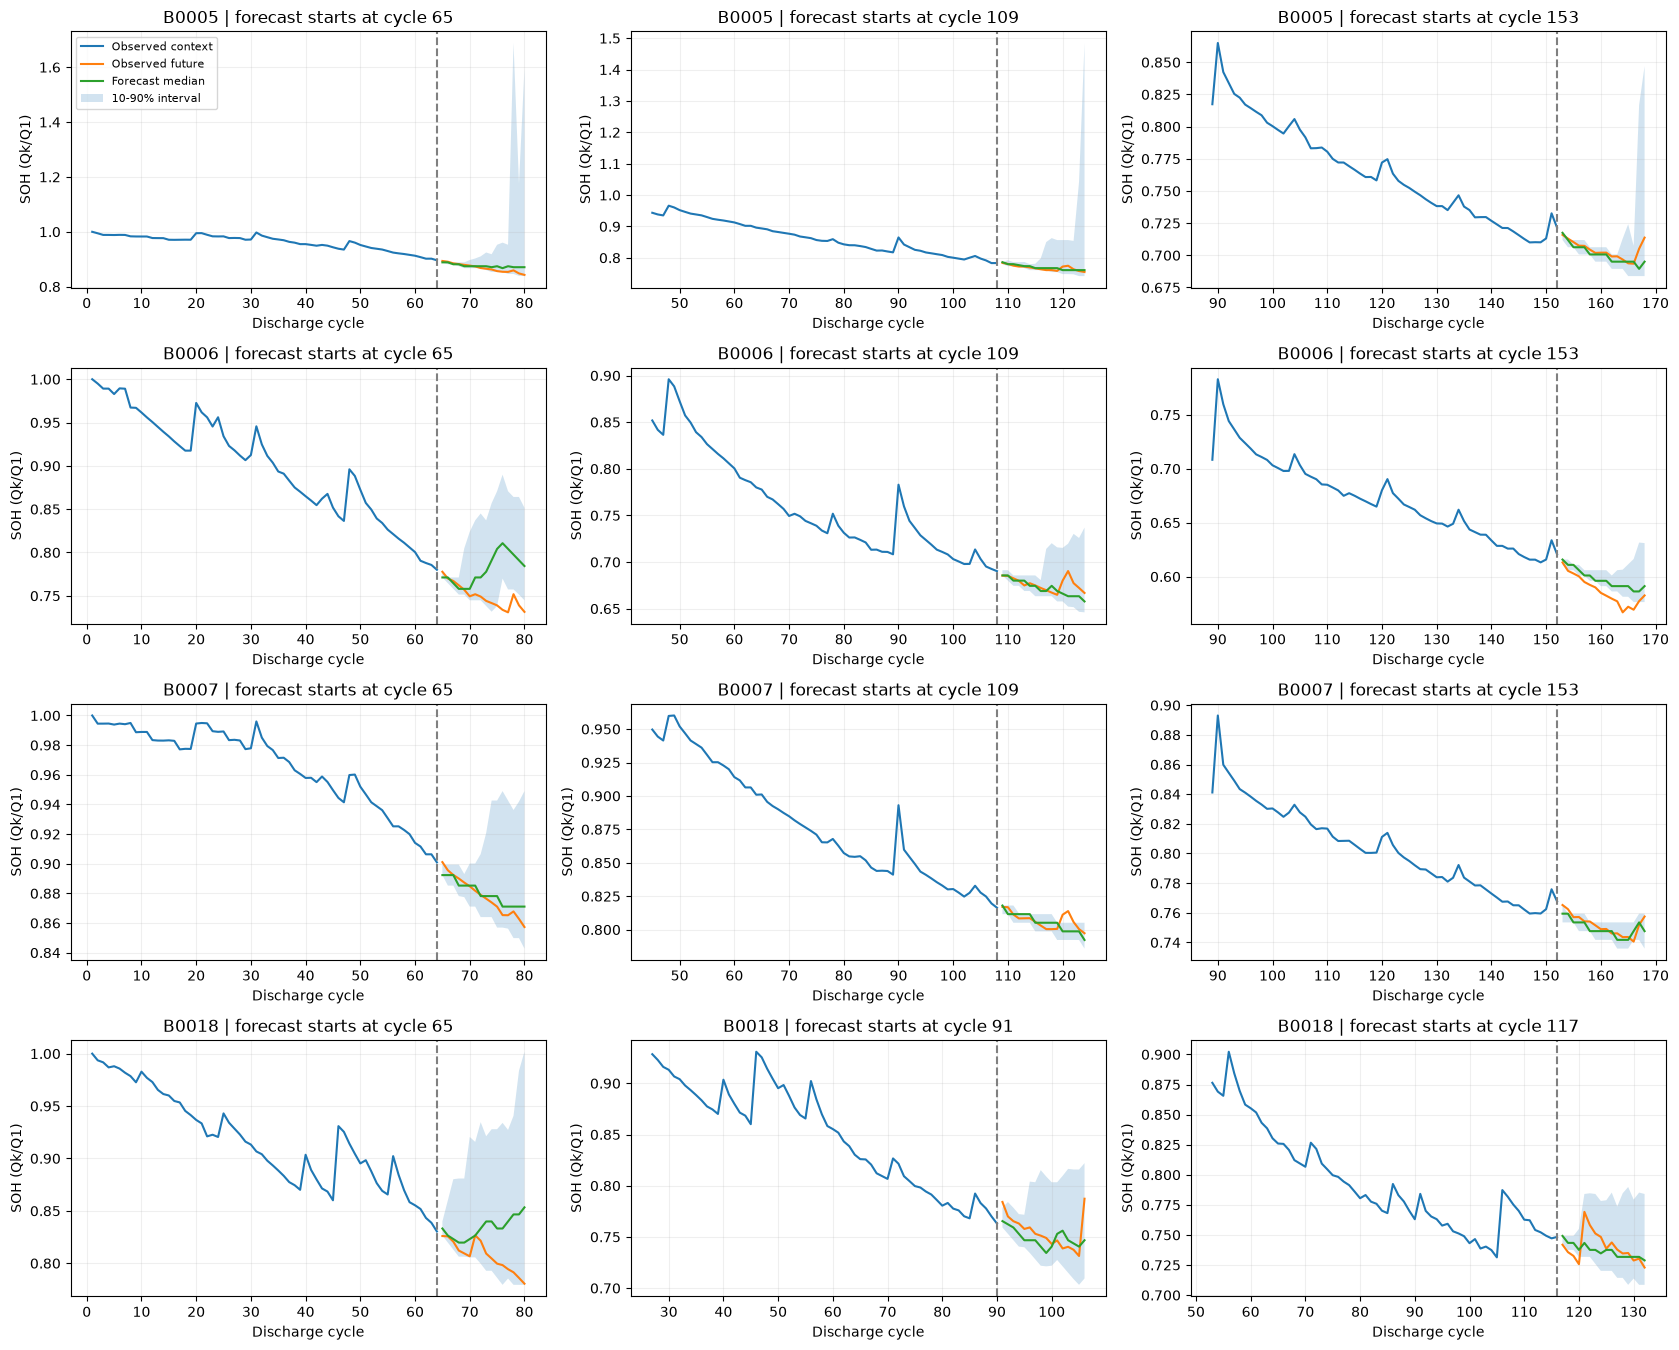

In [7]:
forecast_grid(LORA_RUN)
plt.show()

## 저장된 모델 재사용과 해석

`manifest['folds']`에 adapter 경로가 기록되어 있습니다. `src.soh_experiment.reload_adapter(CONFIG, adapter_path)`로 pinned base model과 adapter를 다시 불러올 수 있습니다. 예측 NPZ에는 context, target, forecast_start, samples, median, mean, q10, q90이 저장됩니다.

- 데이터·모델 revision·환경·seed·예측 설정이 다른 실행을 섞지 않습니다.
- 3개 배터리에서 나온 중첩 윈도우는 수백 개 독립 배터리 사례가 아닙니다.
- Validation 선택 후 전체 데이터로 다시 학습하므로 validation 개선이 평가 배터리 개선을 보장하지 않습니다.
- 학습 seed 1개일 때 보고되는 추론 변동만으로 학습의 안정성이나 통계적 유의성을 주장하지 않습니다.
- 정격 용량이 아닌 첫 관측 용량 기준 SOH입니다. 장기 RUL 및 전압/전류 기반 SOH 추정은 별도 실험입니다.

## 03 갈무리: 기존 LoRA와 EOS loss 제외 비교

아래 결과는 앞의 기존 LoRA 실행과 구분되는 **2026-09-29 고정 진단**입니다. 원본 LoRA는 `20260923T063628Z_lora_2df6cb`입니다. EOS 제외 모델은 같은 데이터·초기화·학습률·선택 epoch·업데이트 수를 사용하되 마지막 출력 EOS label의 loss만 제외했습니다. 입력 EOS는 유지하고, 예측 16개 토큰의 loss 가중치도 유지했습니다. 출력 clipping은 하지 않았습니다.

네 fold, 학습 seed 42 하나, 추론 seed 42/43/44를 사용했습니다. Test 결과로 checkpoint를 선택하지는 않았지만, 이미 관찰한 배터리에 대한 사후 원인 진단이므로 새로운 독립 성능 검증은 아닙니다. 비율 열 `above2_rate`, `coverage80`은 0~1 단위입니다.

In [8]:
DIAGNOSIS = PROJECT_ROOT / "results" / "diagnostics" / "20260929"
diagnostic_metrics = pd.read_csv(DIAGNOSIS / "seed_confirmation" / "metrics.csv")
keys = ["model", "battery", "inference_seed"]
assert len(diagnostic_metrics) == 36 and not diagnostic_metrics.duplicated(keys).any()
assert set(diagnostic_metrics["inference_seed"]) == {42, 43, 44}
score_columns = ["median_rmse", "mean_rmse", "crps", "above2_rate", "coverage80"]
# First average inference seeds, then give the four batteries equal weight.
diagnostic_battery = diagnostic_metrics.groupby(["model", "battery"])[score_columns].mean()
diagnostic_macro = diagnostic_battery.groupby(level="model").mean()
print("Fixed snapshot: 20260929; original XPU runs + EOS-loss ablation; training seed 42")
model_order = ["zero", "original_lora", "without_eos"]
display(diagnostic_macro.loc[model_order].round(6))
median_by_battery = diagnostic_battery["median_rmse"].unstack("model")[model_order]
median_by_battery["without_eos_vs_zero_error_change_pct"] = (
    median_by_battery["without_eos"] / median_by_battery["zero"] - 1
) * 100
display(median_by_battery.round(6))
print("Error change: negative is better. Inference repetitions are not training repetitions.")

Fixed snapshot: 20260929; original XPU runs + EOS-loss ablation; training seed 42


,median_rmse,mean_rmse,crps,above2_rate,coverage80
model,,,,,
zero,0.016307,0.018540,0.008769,0.000063,0.803182
original_lora,0.016176,0.294040,0.017684,0.016753,0.812043
without_eos,0.014894,0.015011,0.007552,0.000008,0.744644


model,zero,original_lora,without_eos,without_eos_vs_zero_error_change_pct
battery,,,,
B0005,0.012601,0.013148,0.010545,-16.317528
B0006,0.018900,0.019232,0.019046,0.771797
B0007,0.011423,0.009454,0.009813,-14.092483
B0018,0.022303,0.022868,0.020174,-9.545490


Error change: negative is better. Inference repetitions are not training repetitions.


### 분리 검증으로 확인한 원인

- **EOS 학습 항:** 이 항만 제외했을 때 네 배터리 모두 평균 예측 RMSE와 CRPS가 회복됐습니다. macro 중앙값 RMSE는 zero-shot보다 8.66% 감소했습니다.
- **재학습 업데이트 증가:** B0005에서 같은 full-data 학습의 81회와 135회를 비교하면 평균 예측 RMSE가 `0.041309 → 0.551199`로 악화됐습니다. epoch를 그대로 옮기면 데이터가 늘어난 만큼 업데이트도 늘어납니다.
- **학습률:** B0005에서 학습률만 `1e-4 → 3e-5`로 낮추어도 폭주가 줄었습니다. 나머지 배터리의 학습률 효과까지 분리한 것은 아닙니다.
- **추론 구현:** B0005 앞 32개 window에서 PEFT generate wrapper를 우회해도 결과가 같고, 같은 checkpoint의 FP32 추론에서도 폭주했습니다. FP32 재학습이나 cache 영향까지 배제한 것은 아닙니다.

다음 표는 **B0005 전체 window, 추론 seed 42 하나**의 비교입니다. 위 세 추론 seed 평균과 구분합니다. `selection_prefix`는 데이터와 업데이트 수가 함께 바뀐 보조 실험이므로 한 요인 비교 표에서 제외했습니다.

,variant,checkpoint,steps,median_rmse,mean_rmse,crps,above2_rate
0,baseline,matched_updates,81,0.011743,0.041309,0.007221,0.001032
1,baseline,final,135,0.013220,0.551199,0.032993,0.035604
2,lower_lr,final,135,0.012229,0.017002,0.006763,0.000126
3,without_eos,final,135,0.010525,0.010318,0.005643,0.000035


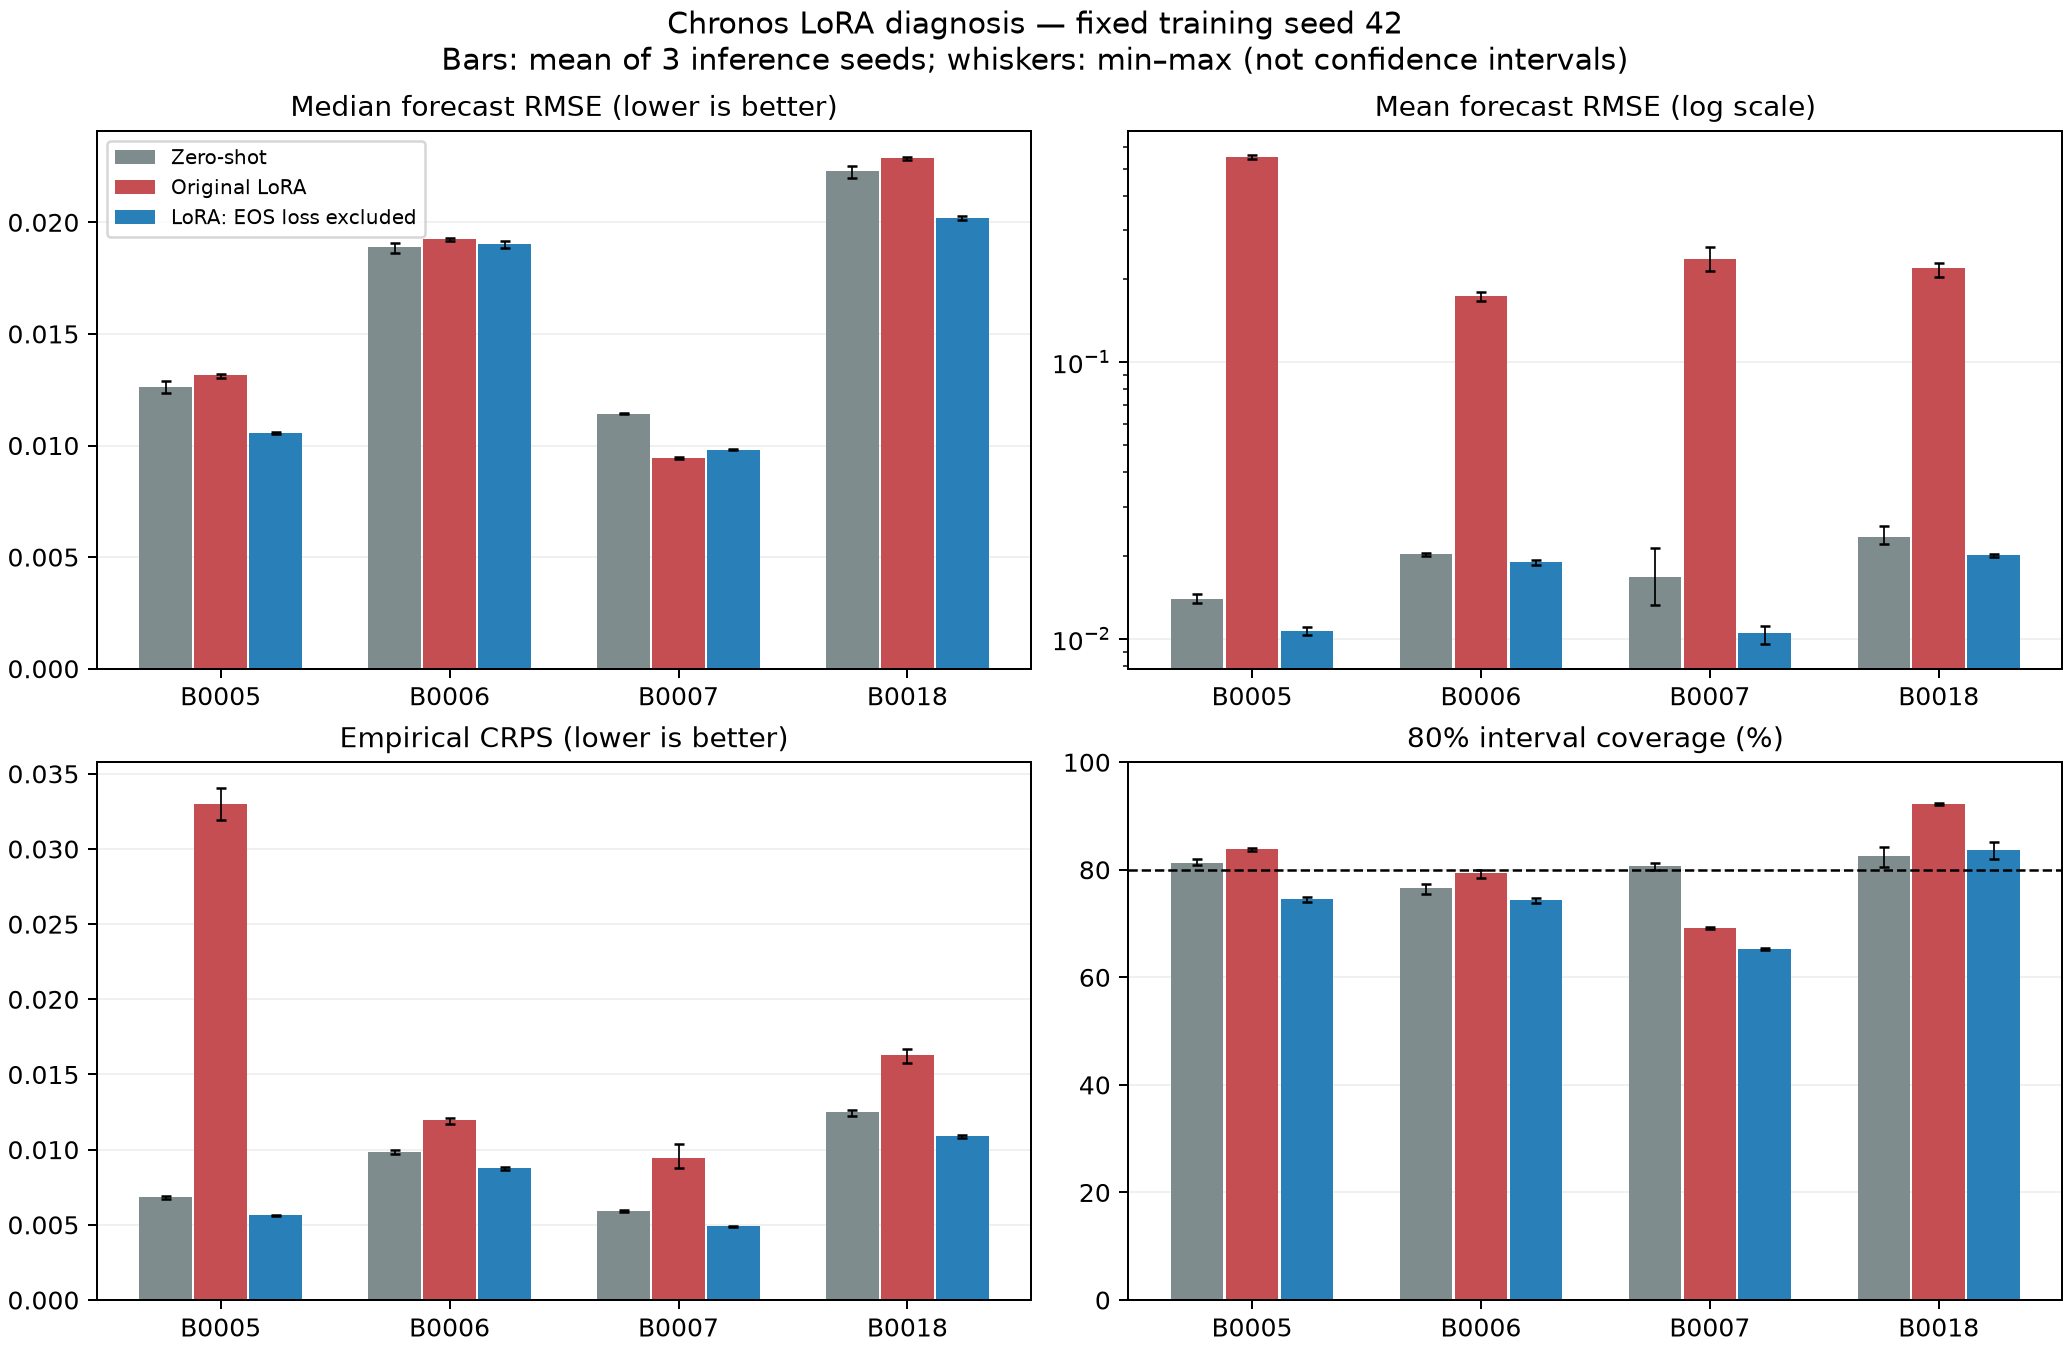

In [9]:
training_controls = pd.read_csv(DIAGNOSIS / "training" / "training_controls.csv")
display(training_controls.loc[
    training_controls["variant"] != "selection_prefix",
    ["variant", "checkpoint", "steps", "median_rmse", "mean_rmse", "crps", "above2_rate"],
].round(6))
from IPython.display import Image
display(Image(filename=str(DIAGNOSIS / "diagnosis_comparison.png"), width=1000))

### 03의 결론과 남은 문제

현재 LoRA의 문제를 단순히 데이터 부족이나 rank 부족으로 결론내릴 수 없습니다. **EOS 목적함수와 학습량의 영향**을 확인했고, EOS 제외 LoRA를 04의 비교 후보로 남깁니다.

- B0006 중앙값 RMSE는 zero-shot보다 약 0.77% 나쁩니다. B0007 중앙값은 기존 LoRA보다 나빠졌습니다.
- EOS 제외의 80% 구간 포함률은 macro 약 74.46%, B0007 약 65.29%로 낮아졌습니다. 정확도 개선과 불확실성 보정은 별도 문제입니다.
- 드문 극단 sample이 여전히 남고, 학습 난수 반복은 아직 하지 않았습니다.
- `cuda-fullft`의 KL 정규화·검증 정책 실험은 다른 프로토콜입니다. 이번 EOS 제외 결과와 개선율을 직접 비교하지 않습니다.

04에서는 같은 base model·장치·분할·EOS 정책으로 zero-shot / LoRA / Full FT를 비교하고, 학습률과 checkpoint는 훈련 배터리 내부 검증으로 고릅니다. 검증한 checkpoint를 그대로 평가하며 별도 refit은 기본 비교에 넣지 않습니다. 현재 진단 점수는 참고값이고, 그 프로토콜에 맞춘 LoRA 대조군을 다시 평가해야 합니다. **04 구현·학습은 이번 갈무리에 포함하지 않았습니다.**

[02·03 정리와 04 비교 조건](../docs/02_03_closeout.md) · [상세 진단 보고서와 원시 결과](../results/diagnostics/20260929/diagnosis.md)